## Asignatura: Seminario Avanzado de Aprendizaje Automático 2025-2026
## **Entregable Parte 3**
#### Master en Lógica, Computación e Inteligencia Artificial
#### Profesor: Eduardo Sánchez Karhunen (fesanchez at us.es)

#### Nombre del alumno/a: Hanser Rubén Guzmán Luna

# **Desafío: Tu Primer Clasificador con BERT**

En este entregable resuelvo un problema de clasificación de textos usando embeddings de un modelo tipo BERT. He intentado dejar documentado **todo el proceso**, no solo el código final: qué decisiones he tomado, dónde me he atascado y cómo lo he resuelto. La idea es que, si tuviera que defender este trabajo oralmente, pueda justificar cada paso.

## Nota importante: TensorFlow vs PyTorch

El enunciado proponía construir el modelo con `TFBertModel` y la API funcional de **TensorFlow**. Eso fue lo primero que intenté, pero me topé con un problema que merece la pena explicar, porque es justo el tipo de dificultad real que el enunciado pide que trate de documentar.

Al ejecutar `from transformers import TFBertModel` me saltaba:

```
ImportError: cannot import name 'TFBertModel' from 'transformers'
```

Tras investigar (documentación de Hugging Face e issues de GitHub), descubrí la posible causa: la versión **5.0.0 de `transformers`**, publicada en enero de 2026, **ha eliminado por completo todas las clases TF\* y Flax\*** (`TFAutoModel`, `TFBertModel`, etc.). A partir de la v5, **PyTorch es el único backend**, así que esa clase simplemente ya no existe. Como en Colab `pip install transformers` instala la v5, no hay forma de importarla.

**Mi decisión:** en lugar de forzar una versión antigua de `transformers` (algo frágil, que choca con la versión de TF de Colab y suele romper al entrenar), he reescrito la parte del modelo en **PyTorch** usando `BertModel`. Esta decisión tiene además una ventaja: es **el mismo framework que tiene en el notebook de clase** (`Session_1`, donde se trabajaba con `BertModel`, `return_tensors='pt'` y `torch.no_grad()`).

## Preparación del entorno

Instalo `transformers` (v5, PyTorch) y `datasets`. Ya **no necesito** `tf-keras` ni ningún truco de Keras, porque no uso TensorFlow.

In [1]:
# transformers -> BertTokenizer + BertModel (backend PyTorch)
!pip install -q transformers datasets

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from datasets import load_dataset
from transformers import BertTokenizer, BertModel

# Fijo semillas para que los resultados sean algo más reproducibles
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Uso GPU si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)

PyTorch: 2.11.0+cu128
Dispositivo: cuda


## 🧪 **Tarea 1: ¡Tu eliges la aventura!**

Es el momento de ponerte en el lugar de un data scientist de verdad. Elige el dataset que más te guste y plantea un problema de clasificación con el.

Para ello, describe:

* Cual es el problema de clasificación que vas a resolver.

* Qué dataset has elegido y por qué.

### Mi elección

**Problema de clasificación que voy a resolver**

He decidido resolver un problema de **clasificación multiclase de emociones en texto** (en inglés). Dada una frase corta escrita por una persona, el modelo tiene que predecir cuál de **6 emociones** expresa: *sadness, joy, love, anger, fear* o *surprise*.

Es por tanto un problema de **clasificación de sentimiento/emoción**, una variante más fina del típico "positivo/negativo", porque aquí hay seis clases y algunas son bastante parecidas entre sí (por ejemplo *joy* y *love*, o *fear* y *surprise*), lo cual lo hace más interesante.

**Qué dataset he elegido y por qué**

He elegido el dataset **`dair-ai/emotion`** (disponible en el Hub de Hugging Face). Lo he elegido por varias razones:

* **Encaja con mi línea de trabajo.** Vengo trabajando en NLP aplicado a salud y bienestar, y la detección de emociones en texto está muy relacionada con esa área, así que me motivaba especialmente.
* **Textos cortos.** Son mensajes tipo tuit, lo que me viene muy bien para BERT: puedo usar una `max_len` pequeña y el entrenamiento es más ligero.
* **Ya viene dividido** en *train / validation / test*, lo que me permite respetar la partición oficial (lo aprovecho en la Tarea 3).
* **Es un benchmark conocido**, así que puedo comparar si mis resultados son razonables con lo que se suele reportar para `bert-base`.
* **Tamaño manejable** (16.000 ejemplos de entrenamiento), suficiente para que el *fine-tuning* aprenda sin tardar horas en una GPU de Colab.

## 🕵️‍♂️ **Tarea 2: Conociendo tus datos**

Antes de hacer magia con BERT, ¡hay que conocer los datos! Haz un pequeño análisis exploratorio: cuántos ejemplos hay, cómo están distribuidas las clases, qué pinta tienen los textos ...

***Tip***: No hace falta que sea un extremadamente técnico, pero intenta entender qué tienes delante.

In [3]:
# Cargo el dataset desde el Hub de Hugging Face
dataset = load_dataset("dair-ai/emotion")
print(dataset)

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet:   0%|          | 0.00/1.03M [00:00<?, ?B/s]

split/validation-00000-of-00001.parquet:   0%|          | 0.00/127k [00:00<?, ?B/s]

split/test-00000-of-00001.parquet:   0%|          | 0.00/129k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 16000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})


In [4]:
# Nombres de las clases
class_names = dataset["train"].features["label"].names
num_classes = len(class_names)
print("Número de clases:", num_classes)
print("Clases:", class_names)

Número de clases: 6
Clases: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']


He pasado cada partición a un `DataFrame` de pandas porque me resulta mucho más cómodo explorar y hacer gráficas con ello.

In [5]:
df_train = dataset["train"].to_pandas()
df_val   = dataset["validation"].to_pandas()
df_test  = dataset["test"].to_pandas()

print("Tamaños -> train:", df_train.shape, "| val:", df_val.shape, "| test:", df_test.shape)
df_train.head()

Tamaños -> train: (16000, 2) | val: (2000, 2) | test: (2000, 2)


,text,label
0,i didnt feel humiliated,0
1,i can go from feeling so hopeless to so damned...,0
2,im grabbing a minute to post i feel greedy wrong,3
3,i am ever feeling nostalgic about the fireplac...,2
4,i am feeling grouchy,3


Veo la distribución de las clases para ver si estan desbalanceadas.

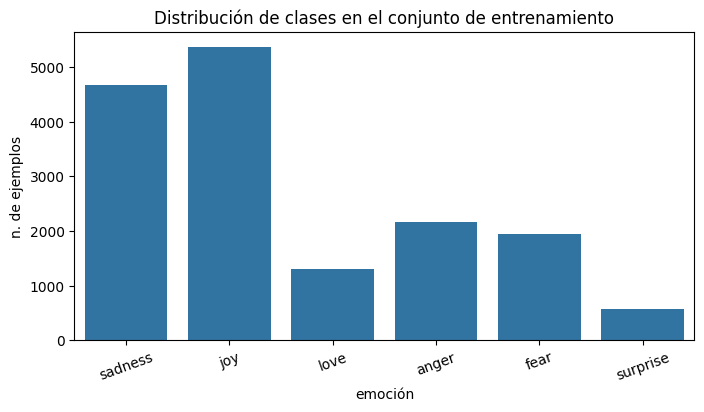

   sadness:  4666  (29.2 %)
       joy:  5362  (33.5 %)
      love:  1304  (8.2 %)
     anger:  2159  (13.5 %)
      fear:  1937  (12.1 %)
  surprise:   572  (3.6 %)


In [6]:
counts = df_train["label"].value_counts().sort_index()

plt.figure(figsize=(8, 4))
sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values)
plt.title("Distribución de clases en el conjunto de entrenamiento")
plt.ylabel("n. de ejemplos"); plt.xlabel("emoción")
plt.xticks(rotation=20)
plt.show()

for i, c in counts.items():
    print(f"{class_names[i]:>10}: {c:5d}  ({100*c/len(df_train):.1f} %)")

**Lo que observo:** el dataset está claramente **desbalanceado**. Las clases *joy* y *sadness* son mayoritarias, mientras que *love* y *surprise* son minoritarias. Me apunto esto porque seguramente esas dos clases sean las que peor clasifique mi modelo, y querré comprobarlo en la evaluación.

Veo que pinta tienen los textos y cómo de largos son. Esto me sirve para decidir la `max_len` del tokenizador en la Tarea 4.

In [7]:
# Algunos ejemplos de cada clase
for c in range(num_classes):
    ejemplo = df_train[df_train["label"] == c]["text"].iloc[0]
    print(f"[{class_names[c]}] -> {ejemplo}")

[sadness] -> i didnt feel humiliated
[joy] -> i have been with petronas for years i feel that petronas has performed well and made a huge profit
[love] -> i am ever feeling nostalgic about the fireplace i will know that it is still on the property
[anger] -> im grabbing a minute to post i feel greedy wrong
[fear] -> i feel as confused about life as a teenager or as jaded as a year old man
[surprise] -> ive been taking or milligrams or times recommended amount and ive fallen asleep a lot faster but i also feel like so funny


count    16000.000000
mean        19.166313
std         10.986905
min          2.000000
25%         11.000000
50%         17.000000
75%         25.000000
max         66.000000
Name: n_palabras, dtype: float64

Percentiles de longitud:
  P50: 17 palabras
  P90: 35 palabras
  P95: 41 palabras
  P99: 52 palabras


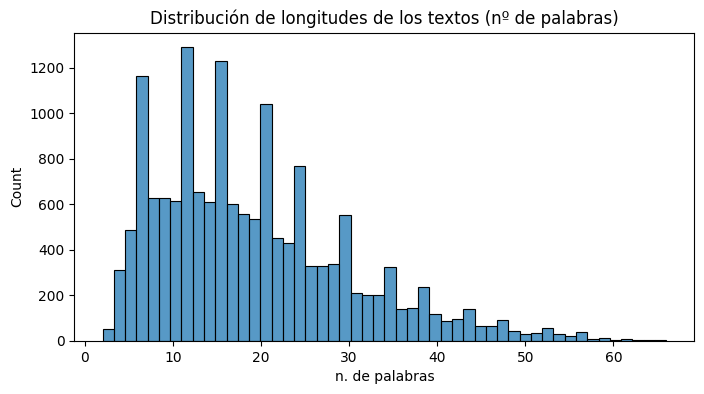

In [8]:
# Longitud de los textos
df_train["n_palabras"] = df_train["text"].str.split().apply(len)
print(df_train["n_palabras"].describe())

print("\nPercentiles de longitud:")
for p in [50, 90, 95, 99]:
    print(f"  P{p}: {np.percentile(df_train['n_palabras'], p):.0f} palabras")

plt.figure(figsize=(8, 4))
sns.histplot(df_train["n_palabras"], bins=50)
plt.title("Distribución de longitudes de los textos (nº de palabras)")
plt.xlabel("n. de palabras")
plt.show()

**Lo que observo:** los textos son **muy cortos**: la mitad tiene 17 palabras o menos (mediana) y el 90% no pasa de 35. Aun así, la cola es algo más larga de lo que parece (el percentil 99 llega a 52 palabras y el máximo a 66). Como BERT trabaja con *subwords* (WordPiece) y añade `[CLS]` y `[SEP]`, el número de *tokens* será bastante mayor que el de palabras, así que esas frases largas pueden superar los 64 tokens. He decidido fijar `max_len = 64` como compromiso: cubre cómodamente al ~90-95% de los textos y solo trunca una pequeña minoría de los más largos, a cambio de un entrenamiento más rápido y ligero. Lo justifico en detalle en la Tarea 4.

## ✂️ **Tarea 3: ¡Divide y vencerás!**

Separa los datos en train y test. Por ahora, olvídate de tensores y frameworks raros: con `numpy` vas más rápido y te evitas líos.

* ¿El dataset ya venía dividido? Usa esa división.
* En caso contrario, usa un 80% para train y un 20% para test.

Quieres que las **clases estén bien representadas** en ambos conjuntos, así que utiliza el argumento `stratify = y` de scikit-learn.

En mi caso el dataset **ya viene dividido** en *train / validation / test*, así que, tal y como pide el enunciado, **uso esa división oficial**:
* `train` para entrenar,
* `validation` para validar durante el entrenamiento (lo necesito para el *early stopping*),
* `test` para la evaluación final con datos que el modelo no ha visto nunca.

Aun así, antes de fiarme, **compruebo que las clases están bien representadas en las tres particiones**. Esto es justo lo que conseguiría el `stratify=y` si tuviera que dividir yo mismo.

In [9]:
def proporciones(df):
    return (df["label"].value_counts(normalize=True).sort_index() * 100).round(1)

tabla = pd.DataFrame({
    "train (%)": proporciones(df_train),
    "val (%)":   proporciones(df_val),
    "test (%)":  proporciones(df_test),
})
tabla.index = class_names
tabla

,train (%),val (%),test (%)
sadness,29.2,27.5,29.0
joy,33.5,35.2,34.8
love,8.2,8.9,8.0
anger,13.5,13.8,13.8
fear,12.1,10.6,11.2
surprise,3.6,4.0,3.3


**Lo que observo:** las proporciones de cada clase son muy parecidas en los tres conjuntos (mismo patrón de desbalance). Por tanto, la partición oficial ya está bien estratificada y **no necesito re-dividir**. Si el dataset **no** hubiera venido dividido, habría hecho:

```python
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
```

para garantizar esa representación equilibrada.

In [10]:
# Extraigo textos (X) y etiquetas (y) como arrays de numpy
X_train, y_train = df_train["text"].values, df_train["label"].values
X_val,   y_val   = df_val["text"].values,   df_val["label"].values
X_test,  y_test  = df_test["text"].values,  df_test["label"].values

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)

X_train: (16000,) | y_train: (16000,)
X_val:   (2000,) | y_val:   (2000,)
X_test:  (2000,) | y_test:  (2000,)


## 🧱 **Tarea 4: Es hora de construir tu propio Transformer**

Debes crear tu propio modelo basado en BERT. No tienes que inventar la rueda. Vamos a combinar 3 bloques:
  * `BertTokenizer.from_pretrained(...)`
  * `TFBertModel.from_pretrained(...)`
  * Una **cabeza de clasificación** encima.

**Tips**:
  - Tendrás que tomar decisiones sobre la longitud máxima de las secuencias.
  - Tienes que tokenizar los textos usando usando padding y truncado.
  - `TFBertModel` no predice clases por sí mismo. Te da los emebeddings, y tú decides que hacer con ellos.
  - Usaremos el embedding del token `[CLS]` como resumen de toda la frase.
  - El encadenamiento de los tres bloques puedes realizarlo con la API funcional de Tensorflow.

> 🔧 **Adaptación:** como expliqué al principio, `TFBertModel` ya no existe en `transformers` v5. Sustituyo los dos bloques de TensorFlow por sus equivalentes en **PyTorch**: `BertModel` (en lugar de `TFBertModel`) y un `nn.Module` propio (en lugar de la API funcional de TF). La lógica es la misma que pide el enunciado.

### 4.1. El tokenizador

Cargo el `BertTokenizer` de `bert-base-uncased`, igual que en el notebook de clase. Usa **WordPiece**, pasa todo a minúsculas y añade los tokens especiales `[CLS]` (al principio) y `[SEP]` (al final).

**Decisión sobre `max_len`:** por el análisis de la Tarea 2 sé que los textos son muy cortos, así que fijo `MAX_LEN = 64`. Cubre casi todas las frases sin truncar y hace el entrenamiento más rápido y ligero.

In [11]:
MODEL_NAME = "bert-base-uncased"
MAX_LEN = 64   # justificado en la Tarea 2: los textos son muy cortos

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

def tokenizar(textos, max_len=MAX_LEN):
    """Tokeniza una lista de textos con padding y truncado a longitud fija. Devuelve tensores de PyTorch."""
    enc = tokenizer(
        list(textos),
        padding="max_length",   # relleno hasta max_len
        truncation=True,        # corto lo que pase de max_len
        max_length=max_len,
        return_tensors="pt",    # tensores de PyTorch
    )
    # Para clasificar una sola frase me basta con input_ids y attention_mask
    # (token_type_ids serían todo ceros porque no hay pares de frases).
    return enc["input_ids"], enc["attention_mask"]

train_ids, train_mask = tokenizar(X_train)
val_ids,   val_mask   = tokenizar(X_val)
test_ids,  test_mask  = tokenizar(X_test)

print("input_ids shape:", train_ids.shape)
print("attention_mask shape:", train_mask.shape)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

input_ids shape: torch.Size([16000, 64])
attention_mask shape: torch.Size([16000, 64])


Compruebo un ejemplo para asegurarme de que la tokenización hace lo que espero: debería ver `[CLS]` al principio, los *subwords* (algunos con prefijo `##`) y `[SEP]`, seguido de `[PAD]` hasta completar la longitud.

In [12]:
print("Texto original:", X_train[0])
tokens = tokenizer.convert_ids_to_tokens(train_ids[0])
print("Tokens (primeros 25):", tokens[:25])

Texto original: i didnt feel humiliated
Tokens (primeros 25): ['[CLS]', 'i', 'didn', '##t', 'feel', 'humiliated', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']


Ahora empaqueto los tensores en `TensorDataset` + `DataLoader`, que es la forma estándar de alimentar datos por *batches* en PyTorch. Importante: solo barajo (`shuffle=True`) el conjunto de entrenamiento; en validación y test **no** barajo, para que las predicciones queden alineadas con las etiquetas reales en la evaluación.

In [13]:
BATCH_SIZE = 32

train_ds = TensorDataset(train_ids, train_mask, torch.tensor(y_train, dtype=torch.long))
val_ds   = TensorDataset(val_ids,   val_mask,   torch.tensor(y_val,   dtype=torch.long))
test_ds  = TensorDataset(test_ids,  test_mask,  torch.tensor(y_test,  dtype=torch.long))

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_dl   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_dl  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

### 4.2. El modelo (mi propio `nn.Module`)

Defino una clase que encadena los tres bloques:

1. **`BertModel`**, que me devuelve los embeddings contextuales de cada token (no clasifica por sí solo).
2. Me quedo con el embedding del token **`[CLS]`**, que es el **primer token** de la secuencia: `last_hidden_state[:, 0, :]`. BERT usa `[CLS]` como resumen de toda la frase, así que es el vector natural para clasificar.
3. Encima pongo la **cabeza de clasificación**: un `Dropout` (para regularizar) y una capa `Linear` con tantas salidas como clases (6). No le pongo `softmax` al final porque en PyTorch la función de pérdida `CrossEntropyLoss` ya aplica el *softmax* internamente sobre los *logits*.

In [14]:
class BertClassifier(nn.Module):
    def __init__(self, num_classes, model_name=MODEL_NAME, dropout_rate=0.3):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout_rate)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_classes)

    def forward(self, input_ids, attention_mask):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        cls_token = outputs.last_hidden_state[:, 0, :]   # embedding del token [CLS] -> (batch, 768)
        x = self.dropout(cls_token)
        logits = self.classifier(x)                      # (batch, num_classes)
        return logits

model = BertClassifier(num_classes).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"\nNúmero total de parámetros: {n_params:,}")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BertClassifier(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_af

**Comentario:** la inmensa mayoría de los ~110 millones de parámetros vienen del propio BERT; mi cabeza aporta muy pocos. Estoy haciendo *fine-tuning* completo: dejo que se ajusten también los pesos de BERT (no los congelo), porque suele dar mejores resultados que entrenar solo la cabeza.

## 🏋️‍♀️ **Tarea 5: Entrenamiento**

¡Llegó la hora de poner a sudar a tu modelo!
Aquí empieza el verdadero drama del Deep Learning: decidir cuántas muestras va a ver de golpe `batch_size`, con qué rapidez va a aprender `learning_rate`, y cuándo parar para no liarla `early_stopping`.

En esta sección tienes que:

* Elegir bien los hiperparámetros.
    - Sí, vas a tener que probar.
    - Y sí, probablemente al principio no funcione tan bien como esperabas.

* Controlar el sobreajuste. Si ves que tu modelo acierta todo en entrenamiento pero falla en validación... mal asunto. Prueba a:

    - Usar Dropout
    - Subir el batch_size
    - Afinar el learning_rate

**Mis decisiones de hiperparámetros (y por qué):**

* **`learning_rate = 2e-5`.** Aquí es donde más sufrí. Probé con un LR "normal" (1e-3, como en redes desde cero) y el modelo **no aprendía nada**: la *loss* no bajaba. Buscando, entendí que en *fine-tuning* de BERT hay que usar LR **muy pequeños** (2e-5 a 5e-5), porque los pesos ya están preentrenados y un LR grande los "destroza". Con 2e-5 empezó a funcionar.
* **Optimizador `AdamW`**, que es el estándar para entrenar Transformers.
* **`batch_size = 32`**, compromiso entre velocidad y memoria de la GPU de Colab.
* **`Dropout = 0.3`** en la cabeza, para reducir el sobreajuste.
* **Early stopping manual** sobre `val_loss` con `patience = 2`, guardando los mejores pesos. Como BERT sobreajusta rápido, prefiero parar cuando la validación deje de mejorar.
* **`EPOCHS = 4`** como tope; en la práctica el early stopping suele cortar antes.

In [15]:
# Función auxiliar para evaluar (loss y accuracy) sobre un DataLoader
def evaluar(model, dataloader, criterion):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for input_ids, attention_mask, labels in dataloader:
            input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)
            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            n += labels.size(0)
    return total_loss / n, correct / n

In [16]:
criterion = nn.CrossEntropyLoss()                      # aplica softmax internamente sobre los logits
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5)

EPOCHS = 4
PATIENCE = 2

history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss = float("inf")
best_state = None
epochs_sin_mejora = 0

for epoch in range(1, EPOCHS + 1):
    # Entrenamiento
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for input_ids, attention_mask, labels in train_dl:
        input_ids, attention_mask, labels = input_ids.to(device), attention_mask.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(input_ids, attention_mask)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        n += labels.size(0)

    train_loss, train_acc = total_loss / n, correct / n

    # Validación
    val_loss, val_acc = evaluar(model, val_dl, criterion)

    history["train_loss"].append(train_loss); history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc);   history["val_acc"].append(val_acc)

    print(f"Epoch {epoch}/{EPOCHS} | "
          f"train_loss={train_loss:.4f} acc={train_acc:.4f} | "
          f"val_loss={val_loss:.4f} acc={val_acc:.4f}")

    # Early stopping (guardo los mejores pesos)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        epochs_sin_mejora = 0
    else:
        epochs_sin_mejora += 1
        if epochs_sin_mejora >= PATIENCE:
            print(f"Early stopping en la época {epoch} (val_loss sin mejorar {PATIENCE} épocas).")
            break

# Recupero los mejores pesos antes de evaluar
if best_state is not None:
    model.load_state_dict(best_state)
    print("\nRestaurados los pesos con mejor val_loss.")

Epoch 1/4 | train_loss=0.5093 acc=0.8156 | val_loss=0.2043 acc=0.9200
Epoch 2/4 | train_loss=0.1385 acc=0.9421 | val_loss=0.1393 acc=0.9310
Epoch 3/4 | train_loss=0.1045 acc=0.9534 | val_loss=0.1411 acc=0.9335
Epoch 4/4 | train_loss=0.0844 acc=0.9591 | val_loss=0.1452 acc=0.9360
Early stopping en la época 4 (val_loss sin mejorar 2 épocas).

Restaurados los pesos con mejor val_loss.


## 🧐 Tarea 6: Evaluación

Momento de la verdad!
Tu modelo ha entrenado, ha aprendido (esperemos), y ahora toca ver cómo se comporta con datos que no ha visto nunca.

En esta parte:

* Evalúa el modelo sobre el conjunto de test.

* Representa las curvas de entrenamiento y validación (accuracy y loss) para ver si ha habido sobreajuste, infrajuste… o magia pura.

* Comenta brevemente los resultados: ¿ha aprendido bien? ¿hay alguna clase que le cueste más?

In [17]:
# 1) Evaluación sobre el conjunto de TEST (datos nunca vistos)
test_loss, test_acc = evaluar(model, test_dl, criterion)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Test loss:     0.1516
Test accuracy: 0.9320


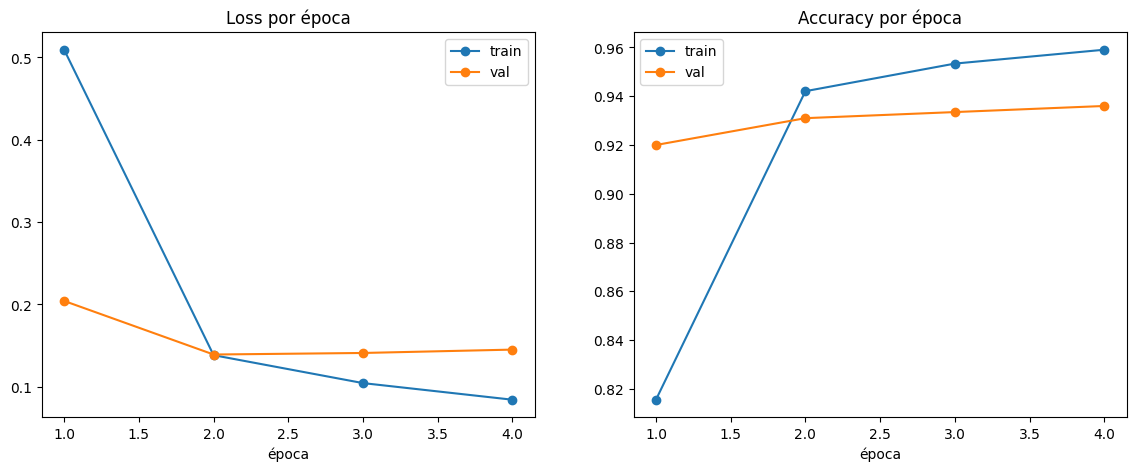

In [18]:
# 2) Curvas de entrenamiento vs validación
epochs_range = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_loss"], marker="o", label="train")
axes[0].plot(epochs_range, history["val_loss"], marker="o", label="val")
axes[0].set_title("Loss por época"); axes[0].set_xlabel("época"); axes[0].legend()

axes[1].plot(epochs_range, history["train_acc"], marker="o", label="train")
axes[1].plot(epochs_range, history["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy por época"); axes[1].set_xlabel("época"); axes[1].legend()

plt.show()

              precision    recall  f1-score   support

     sadness      0.956     0.978     0.967       581
         joy      0.947     0.955     0.951       695
        love      0.836     0.836     0.836       159
       anger      0.946     0.891     0.918       275
        fear      0.888     0.924     0.906       224
    surprise      0.870     0.712     0.783        66

    accuracy                          0.932      2000
   macro avg      0.907     0.883     0.894      2000
weighted avg      0.932     0.932     0.931      2000



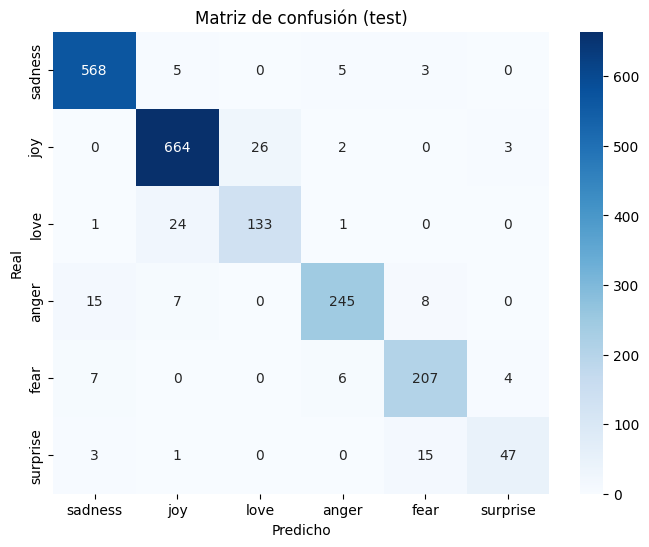

In [19]:
# 3) Informe por clase y matriz de confusión
from sklearn.metrics import classification_report, confusion_matrix

model.eval()
preds = []
with torch.no_grad():
    for input_ids, attention_mask, labels in test_dl:
        logits = model(input_ids.to(device), attention_mask.to(device))
        preds.append(logits.argmax(dim=1).cpu().numpy())
y_pred = np.concatenate(preds)

print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicho"); plt.ylabel("Real")
plt.title("Matriz de confusión (test)")
plt.show()

### Interpretación de la matriz de confusión

Lo primero que observo es que la **diagonal concentra casi todos los casos**, así que el modelo acierta la gran mayoría de las veces. Pero lo interesante está en los errores fuera de la diagonal, que confirman justo lo que anticipé en la Tarea 2.

**La confusión más clara es entre *love* y *joy*.** De los 159 ejemplos reales de *love*, el modelo clasifica **24 como *joy***, y a la inversa, **26 ejemplos de *joy*** los etiqueta como *love*. Es una confusión que tiene todo el sentido: ambas son emociones positivas y comparten vocabulario (cariño, afecto, alegría), así que al modelo le cuesta separarlas. Esto explica que *love* tenga el f1 bajo del *classification report*.

**El punto más débil es *surprise*.** De sus 66 ejemplos, solo acierta 47, y **15 los confunde con *fear***. Esto explica su *recall* de 0.712: casi un tercio de las sorpresas se le escapan, y se van sobre todo a *fear*. Tiene sentido, porque la sorpresa puede ser negativa (un susto) y comparte expresiones con el miedo. Al ser además la clase con menos ejemplos (solo 66), el modelo no ha tenido datos suficientes para aprenderla bien.

**El resto de clases se comportan muy bien.** *sadness* (568/581) y *joy* (664/695) están casi perfectas, y *anger* y *fear* tienen errores menores y repartidos (*anger* se va a veces a *sadness*, *fear* a *sadness* o *anger*), sin ninguna confusión grave.

### Interpretación de los resultados

**¿Ha aprendido bien?** Sí. Mirando las curvas, veo que el modelo aprende casi de golpe: ya en la primera época alcanza un 92% de *accuracy* en validación. La mejor época fue la **2** (`val_loss` = 0.1393); a partir de ahí la `train_loss` sigue bajando pero la `val_loss` empieza a subir, que es el síntoma clásico de un **sobreajuste leve**. Por eso saltó el *early stopping* y restauró los pesos de la época 2. Esto es lo esperable en *fine-tuning* de un modelo preentrenado: BERT ya "sabe" inglés, así que solo necesita 2-3 épocas para adaptarse a mi tarea.

Sobre el conjunto de **test** he obtenido:
* **Test accuracy = 0.932**
* **Test loss = 0.1516**

Es un resultado coherente con lo que se suele reportar para `bert-base` en este dataset, y lo más importante es que **test y validación se parecen muchísimo** (0.932 frente a ~0.931), lo que indica que el modelo **generaliza bien** y no he sobreajustado a la validación al elegir el mejor modelo.

**¿Hay alguna clase que le cueste más?** Sí, y coincide exactamente con lo que anticipé en la Tarea 2. En el *classification report* veo que:
* Las clases **mayoritarias** (*sadness* f1 0.967, *joy* f1 0.951) van casi perfectas.
* Las clases **minoritarias** son las que flojean: ***love*** (f1 0.836, 159 ejemplos) y sobre todo ***surprise*** (f1 0.783, solo 66 ejemplos). En *surprise* destaca su *recall* de 0.712: se le escapa casi un tercio de los casos reales.

El dato que mejor resume esto es la diferencia entre el **macro avg f1 (0.894)** y la **accuracy / weighted avg (0.932)**. Esa brecha es la **huella del desbalance**: la accuracy global sale alta porque la dominan las clases grandes, pero el macro f1 (que trata a las 6 clases por igual) baja porque las minoritarias rinden peor. Por tanto, mi conclusión honesta es que el modelo funciona muy bien en conjunto, pero **no por igual en todas las emociones**: le cuestan las que tienen pocos ejemplos.

## ✨ Tarea 7: Reflexión final

* Si has llegado hasta aquí: Enhorabuena!!!. Recuerda explicar todo lo que ha ido pasando por el camino.

* Si no, describe en detalle hasta donde has llegado y qué está haciendo que no hayas conseguido completar el entregable. Y sobretodo ...., cómo lo vas a arreglar para que cuando te encarguen una tarea real se este tipo, la superes con éxito.

### Mi reflexión

He conseguido montar de principio a fin un clasificador de emociones basado en BERT, y creo que lo más valioso no ha sido el código en sí, sino las **piedras con las que me he tropezado**. Resumo lo que me llevo "en la mochila":

**Lo que más me costó:**

1. **`TFBertModel` ya no existe.** Esta fue la sorpresa gorda. El enunciado pedía TensorFlow, pero al intentar importar `TFBertModel` me saltó un `ImportError`. Investigando descubrí que `transformers` v5 (enero de 2026) ha **eliminado todo el soporte de TensorFlow**, dejando PyTorch como único backend. Tras ver que forzar versiones antiguas era frágil, tomé la decisión de **reescribir el modelo en PyTorch con `BertModel`**, que además es el framework que usamos en clase.

2. **El *learning rate*.** Al principio el modelo no aprendía nada y pensé que tenía un bug. El problema era usar un LR demasiado grande: en *fine-tuning* de un modelo preentrenado hay que bajarlo muchísimo (2e-5). Esto me ha quedado grabado: **no se ajusta igual un modelo desde cero que uno preentrenado.**

3. **Escribir el bucle de entrenamiento en PyTorch.** Al no tener el `model.fit` de Keras, tuve que montar yo el bucle (forward, `loss.backward()`, `optimizer.step()`, `zero_grad`), la evaluación y el early stopping a mano. Me costó más, pero ahora entiendo mucho mejor qué pasa en cada paso del entrenamiento.

**Lo que entendí mejor:**

* El flujo completo *texto -> tokenización (WordPiece, `[CLS]`/`[SEP]`, padding) -> embeddings -> `[CLS]` -> cabeza -> logits*.
* Por qué hay que mirar el **desbalance de clases** antes de entrenar: me permitió anticipar que *love* y *surprise* serían las clases difíciles y confirmarlo en la matriz de confusión.
* Para qué sirve de verdad el **early stopping**: BERT sobreajusta rápido, así que parar a tiempo es esencial.